In [12]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244081109
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] py311
[学号] 20244081109
[机器指纹] 21935ea21d1fabf1
[RUN_ID] 20244081109-21935ea21d1fabf1


# 一、围绕半圆定律

半圆密度：当 |x| ≤ 2 时 f(x) = sqrt(4 - x^2) / (2π)，当 |x| > 2 时 f(x) = 0。

## 题目 1　`wigner_density(x)`

编写 wigner_density(x)，接收一个整数或浮点数，返回半圆密度在 x 处的值，返回值为浮点数。不需要检查输入类型；函数应同时适用于 Python 和 NumPy 的整数、浮点数。计算平方根时使用 numpy.sqrt，不要使用 math.sqrt。

解答：一进函数先 x = float(x)，把 Python 的 int、NumPy 的 np.int64 和 np.float64 都统一成 Python 浮点，返回值自然也是 float；然后判断 abs(x) > 2 直接返回 0.0（|x| = 2 时 sqrt(4-4) = 0，落进公式也对）；剩下的平方根交给 np.sqrt。


In [13]:
import numpy as np


def wigner_density(x):
    """半圆密度：|x| <= 2 时返回 sqrt(4 - x^2)/(2*pi)，否则返回 0。"""
    x = float(x)                    # 同时兼容 Python / NumPy 的整数、浮点数
    if abs(x) > 2:                  # 圆外密度为 0
        return 0.0
    return float(np.sqrt(4.0 - x * x) / (2.0 * np.pi))


for x in [-3, -1, 0, 1, 3]:
    print(f"wigner_density({x}) = {wigner_density(x):.4f}")
print("核对：f(0) 应等于 1/pi，即", round(1 / np.pi, 4))

wigner_density(-3) = 0.0000
wigner_density(-1) = 0.2757
wigner_density(0) = 0.3183
wigner_density(1) = 0.2757
wigner_density(3) = 0.0000
核对：f(0) 应等于 1/pi，即 0.3183


## 题目 2　`generate_wigner(n)`

编写 generate_wigner(n)，接收正整数 n，返回一个随机生成的 n × n 的 Wigner 矩阵，可以使用 NumPy 的二维数组或矩阵表示。若输入不是整数或不是正数，应抛出合适的异常。

解答：对所有 1 ≤ i ≤ j ≤ n 独立抽 Z_ij ~ N(0, 1/n)，再令 Z_ji = Z_ij。三个要点：（1）bool 是 int 的子类，先排除；非整数抛 TypeError，n ≤ 0 抛 ValueError。（2）np.random.normal 的第二个参数是标准差，而题目给的是方差 1/n，所以要传 np.sqrt(1/n)。（3）整块采样后取上三角 np.triu，再用 Z + Z.T 镜像到下半部分，此时对角线被加了两次，最后减一次 np.diag(np.diag(Z))。

In [14]:
def generate_wigner(n):
    """生成 n×n Wigner 矩阵：i <= j 的元素取 N(0, 1/n)，再对称化。"""
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError(f"n 必须是整数，收到 {type(n).__name__}")
    if n <= 0:
        raise ValueError(f"n 必须是正整数，收到 {n}")

    n = int(n)
    sigma = np.sqrt(1.0 / n)                 # 方差 1/n  =>  标准差 1/sqrt(n)
    A = np.random.normal(0.0, sigma, size=(n, n))
    Z = np.triu(A)                           # 只保留 i <= j 的部分
    Z = Z + Z.T - np.diag(np.diag(Z))        # 镜像到下半部分，对角线别重复加
    return Z


for n in [1, 2, 100]:
    Z = generate_wigner(n)
    print(f"n = {n}：形状 {Z.shape}，是否对称 {np.allclose(Z, Z.T)}")

print()
print(np.round(generate_wigner(2), 3))

print()
for n in [0, -1, 2.5]:
    try:
        generate_wigner(n)
        print(n, "没有抛异常")
    except Exception as e:
        print(n, "->", type(e).__name__)

n = 1：形状 (1, 1)，是否对称 True
n = 2：形状 (2, 2)，是否对称 True
n = 100：形状 (100, 100)，是否对称 True

[[-0.12  -0.056]
 [-0.056 -0.42 ]]

0 -> ValueError
-1 -> ValueError
2.5 -> TypeError


## 题目 3　`get_spectrum(matrix)`

编写 get_spectrum(matrix)，接收 NumPy 矩阵或二维 NumPy 数组，返回包含其全部特征值的 NumPy 数组，按非递减顺序排列。本函数不需要检查输入类型。

解答：先用 np.asarray(matrix, dtype=float) 把 np.matrix、数组、列表统一成普通二维数组；再用 np.linalg.eigvalsh 求特征值，它专供对称矩阵，比 eigvals 快，而且结果一定是实数（Wigner 矩阵的 n 个特征值都是实根）；最后 np.sort 保证非递减。


In [15]:
def get_spectrum(matrix):
    """返回矩阵的全部特征值，按非递减顺序排列。"""
    A = np.asarray(matrix, dtype=float)
    eigenvalues = np.linalg.eigvalsh(A)     # 实对称矩阵专用
    return np.sort(eigenvalues)


Z = generate_wigner(2)
print("矩阵：")
print(np.round(Z, 3))
print("特征值：", np.round(get_spectrum(Z), 4))

矩阵：
[[ 0.918 -0.235]
 [-0.235 -1.254]]
特征值： [-1.279   0.9431]


## 题目 4　四个纵向子图

画一张包含四个纵向排列子图的图。对 n = 100, 200, 500, 1000，每个子图分别用蓝色、标准化的直方图展示随机 n × n Wigner 矩阵的特征值，并叠加红色的半圆密度曲线。根据图形说明：n 大约达到多少时，半圆密度能较好地拟合特征值分布？（可选：用 Kolmogorov–Smirnov 检验做更严格的比较。）

解答：用 plt.subplots(4, 1) 得到纵向排列的四个子图；直方图必须 density=True，纵轴才是概率密度，才能和 f(x) 直接比，这就是"标准化"；红色曲线只在 [-2, 2] 上取点画，区间外密度为 0 所以不画；四个子图统一 set_xlim，方便比较曲线是否在 ±2 处落到 0。

C:\Users\yy\AppData\Local\Temp\ipykernel_19584\1068408727.py:22: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yy\AppData\Local\Temp\ipykernel_19584\1068408727.py:22: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yy\AppData\Local\Temp\ipykernel_19584\1068408727.py:22: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yy\AppData\Local\Temp\ipykernel_19584\1068408727.py:22: UserWarning: Glyph 23494 (\N{CJK UNIFIED IDEOGRAPH-5BC6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yy\AppData\Local\Temp\ipykernel_19584\1068408727.py:22: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yy\AppData\Local\Temp\ipykernel_19584\1068408727.py:22: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT P

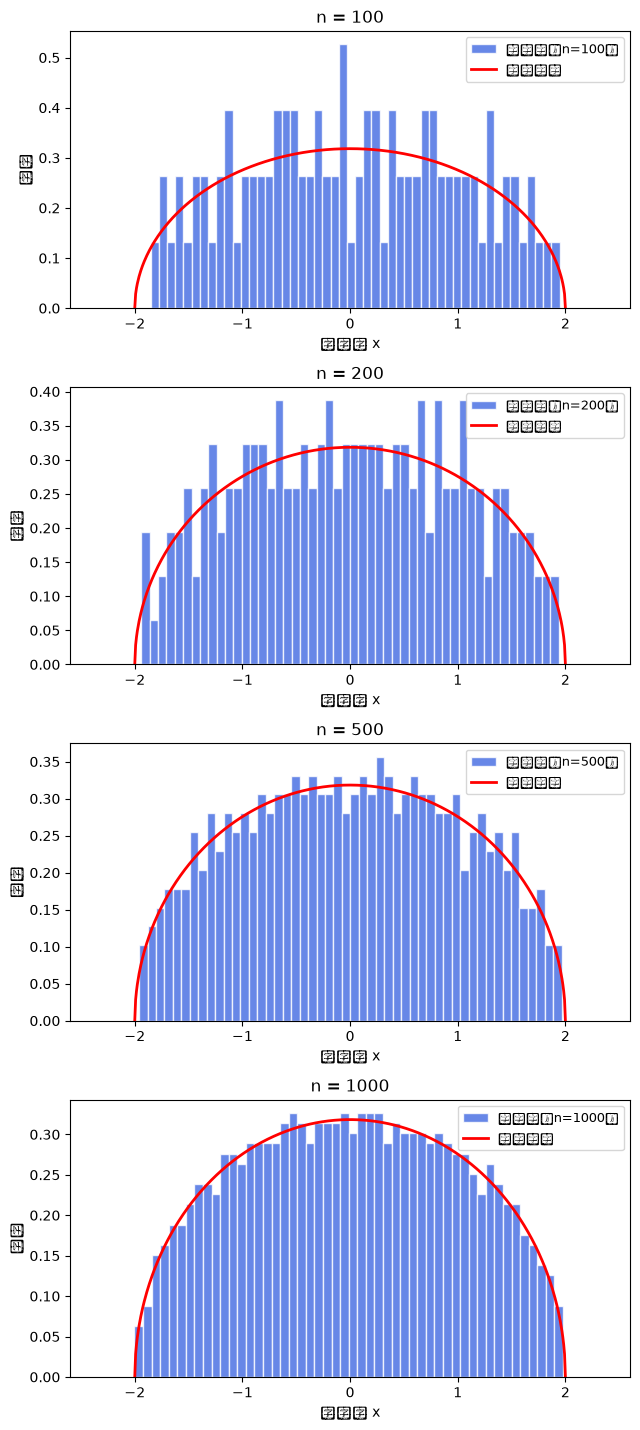

In [16]:
import matplotlib.pyplot as plt

np.random.seed(0)                 # 固定随机种子，结果可复现

n_values = [100, 200, 500, 1000]
x_grid = np.linspace(-2, 2, 500)
y_grid = np.array([wigner_density(x) for x in x_grid])

fig, axes = plt.subplots(len(n_values), 1, figsize=(6.5, 3.6 * len(n_values)))

for ax, n in zip(axes, n_values):
    eigs = get_spectrum(generate_wigner(n))
    ax.hist(eigs, bins=50, density=True, color="royalblue", alpha=0.8,
            edgecolor="white", label=f"特征值（n={n}）")
    ax.plot(x_grid, y_grid, color="red", lw=2, label="半圆密度")
    ax.set_xlim(-2.6, 2.6)
    ax.set_title(f"n = {n}")
    ax.set_xlabel("特征值 x")
    ax.set_ylabel("密度")
    ax.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

结论：n = 100 时直方图已经是半圆拱形，但柱子高低起伏明显，±2 附近的边缘也不干净；n = 200 轮廓更接近，中间仍有抖动；n = 500 已经相当平滑，几乎贴合红色曲线，只在 ±2 端点附近略有偏差（端点处密度趋于 0，有分箱误差）；n = 1000 视觉上基本重合。
所以 n 大约到 500 时，半圆密度就能较好地拟合特征值分布，n = 1000 更平滑但提升有限。这与随机矩阵理论中收敛速度约 O(n^(-1/2)) 的结论一致，误差随 n 增大而缓慢下降，要把曲线磨平只能继续加阶数。

Kolmogorov–Smirnov 检验：半圆密度的分布函数有解析式 F(x) = 1/2 + (x*sqrt(4 - x^2) + 2*arcsin(x/2)) / (2π)，参数已知，可以直接做单样本 KS 检验，D 越小说明经验分布越接近理论分布。

In [17]:
try:
    from scipy.stats import kstest

    def semicircle_cdf(x):
        x = np.clip(np.asarray(x, dtype=float), -2, 2)
        return 0.5 + (x * np.sqrt(4 - x ** 2) + 2 * np.arcsin(x / 2)) / (2 * np.pi)

    for n in n_values:
        eigs = get_spectrum(generate_wigner(n))
        D, p = kstest(eigs, semicircle_cdf)
        print(f"n = {n}：D = {D:.4f}，p = {p:.4f}")
except ImportError:
    print("未安装 scipy，跳过可选的 KS 检验")

n = 100：D = 0.1693，p = 0.0056
n = 200：D = 0.1719，p = 0.0000
n = 500：D = 0.1620，p = 0.0000
n = 1000：D = 0.1627，p = 0.0000


# 二、Conway 的生命游戏

生命游戏在一个 m × n 棋盘上进行，棋盘用 NumPy 的二维数组表示：活细胞记为 1，死细胞记为 0。每一步按以下规则同时更新所有细胞：

- 活细胞有少于两个活邻居时死亡；
- 活细胞有两个或三个活邻居时继续存活；
- 活细胞有多于三个活邻居时死亡；
- 死细胞恰好有三个活邻居时复活；
- 其他死细胞保持死亡。

每个细胞有上、下、左、右和四个对角方向共八个邻居，棋盘采用环绕边界。

## 题目 1　`is_valid_board(board)`

编写 is_valid_board(board)，接收一个 NumPy ndarray，若它是有效的生命游戏棋盘（二维、元素仅为 0 或 1）则返回 Python 布尔值 True，否则返回 False。

解答：依次检查三件事——是不是 ndarray、是不是二维、元素是否只取 0 或 1。最后一步用 np.all((board == 0) | (board == 1))，逐个判断"等于 0 或等于 1"再整体取 all。返回值要写成 True / False 字面量，因为 np.all 返回的是 np.bool_，不是 Python 的 bool。


In [18]:
def is_valid_board(board):
    """有效棋盘：二维 ndarray，且元素只取 0 或 1。"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    if not np.all((board == 0) | (board == 1)):
        return False
    return True


print(is_valid_board(np.array([[1, 0], [0, 1]])))          # 二维、只有 0/1 -> True
print(is_valid_board(np.array([[0, 1, 0],
                               [1, 0, 1],
                               [0, 1, 0]])))               # 3×3 -> True
print(is_valid_board(np.array([[1, 2], [0, 1]])))          # 有 2 -> False
print(is_valid_board(np.array([1, 0, 1])))                 # 一维 -> False
print(is_valid_board([[1, 0], [0, 1]]))                    # 不是 ndarray -> False

True
True
False
False
False


## 题目 2　`gol_step(board)`

编写 gol_step(board)，接收一个 m × n 棋盘，返回同样大小的 NumPy 数组，表示下一步的棋盘。函数应先检查输入是否为有效棋盘，无效时抛出合适的异常。计算某个细胞的下一个状态时，应使用原棋盘中的邻居状态。

解答：（1）先 if not is_valid_board(board): raise ValueError(...)。（2）算邻居数：对八个方向 (di, dj)，用 np.roll(b, di, axis=0) 和 np.roll(b, dj, axis=1) 平移棋盘再累加；np.roll 本身就是环绕的，越界元素从另一头补回来，所以边界环绕自动满足。（3）同时更新：邻居数从旧数组 b 算，新棋盘由布尔运算一次生成，不会边算边改。（4）规则布尔化：活着且邻居为 2 或 3 保持 alive & ((nb == 2) | (nb == 3))，死着且邻居为 3 复活 ~alive & (nb == 3)，两者取或。

In [19]:
def gol_step(board):
    """返回生命游戏的下一步棋盘（环绕边界，同时更新）。"""
    if not is_valid_board(board):
        raise ValueError("无效棋盘：需要二维 ndarray，且元素只能是 0 或 1")

    b = board.astype(np.int64)               # 转整数再相加
    neighbours = np.zeros_like(b)

    for di in (-1, 0, 1):                    # 八个方向，跳过自己
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbours += np.roll(np.roll(b, di, axis=0), dj, axis=1)

    alive = b == 1
    nxt = (alive & ((neighbours == 2) | (neighbours == 3))) | (~alive & (neighbours == 3))
    return nxt.astype(board.dtype)


# 2×2 方块：永远不变
block = np.zeros((4, 4), dtype=int)
block[1:3, 1:3] = 1
print(block)
print("下一步：")
print(gol_step(block))
print("是否不变：", np.array_equal(gol_step(block), block))

# 三个连成一线：每步转向，两步回到原样
blinker = np.zeros((5, 5), dtype=int)
blinker[2, 1:4] = 1
print()
print("三连：")
print(gol_step(blinker))
print("两步后回到原样：", np.array_equal(gol_step(gol_step(blinker)), blinker))

[[0 0 0 0]
 [0 1 1 0]
 [0 1 1 0]
 [0 0 0 0]]
下一步：
[[0 0 0 0]
 [0 1 1 0]
 [0 1 1 0]
 [0 0 0 0]]
是否不变： True

三连：
[[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]
两步后回到原样： True


## 题目 3　`draw_gol_board(board)`

编写 draw_gol_board(board)，将棋盘画成 m × n 个方格：活细胞为黑色，死细胞为白色。图中不显示网格线、轴标签或轴刻度。可以使用 plt.xticks()、plt.yticks() 和 plt.get_cmap() 等函数。

解答：用 plt.imshow 把数组画成图像，一个元素就是一个方格；配色用 plt.get_cmap("gray_r")，"gray" 是 0 黑 1 白，加 _r 反向，正好 0 白 1 黑，再设 vmin=0、vmax=1 固定色阶；用 plt.xticks([]) 和 plt.yticks([]) 清掉刻度和标签，plt.grid(False) 关网格线，最后把四个 spines 边框设为不可见。

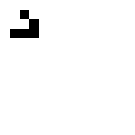

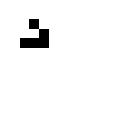

In [20]:
def draw_gol_board(board):
    """把棋盘画成 m×n 方格：活细胞黑色、死细胞白色，无网格线和刻度。"""
    if not is_valid_board(board):
        raise ValueError("无效棋盘：需要二维 ndarray，且元素只能是 0 或 1")

    m, n = board.shape
    plt.figure(figsize=(n / 8, m / 8))
    plt.imshow(board, cmap=plt.get_cmap("gray_r"), vmin=0, vmax=1,
               interpolation="nearest")
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    for spine in plt.gca().spines.values():
        spine.set_visible(False)
    plt.show()


# 滑翔机：每 4 步沿对角线平移一格
glider = np.zeros((12, 12), dtype=int)
glider[0:3, 0:3] = np.array([[0, 1, 0],
                             [0, 0, 1],
                             [1, 1, 1]])
draw_gol_board(glider)

for _ in range(4):
    glider = gol_step(glider)
draw_gol_board(glider)

两张图对比可以看到，4 步之后滑翔机整体向右下平移了 1 格、形状不变，说明环绕边界和同时更新都写对了。另外 2×2 方块（静物）和三点直线（周期 2 的振荡子）分别是生命游戏里最小的稳定结构和最小振荡结构。

# 三、使用 pandas DataFrame

本题练习读取、修改和保存 DataFrame，以及按组汇总数据。提前把 iris.csv 放到与本 Notebook 相同的目录下。

## 题目 1　读入数据

下载 iris.csv，使用 pandas 将它读入为 DataFrame；CSV 的第一行是列标题。回答：数据集有多少个数据点？每列是什么数据类型？列名是什么？数据中有多少种花卉？

解答：pd.read_csv 默认把第一行当列名；df.shape 看行数，df.dtypes 看每列类型，df.columns.tolist() 看列名，df["species"].nunique() 看花卉种数。


In [21]:
import pandas as pd

df = pd.read_csv("iris.csv")

print("形状 (行, 列)：", df.shape)
print("列名：", df.columns.tolist())
print()
print(df.dtypes)
print()
print(df.head())
print()
print("花卉种类：", df["species"].unique())
print("共", df["species"].nunique(), "种")
print(df["species"].value_counts())

形状 (行, 列)： (150, 5)
列名： ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

花卉种类： <StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str
共 3 种
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 题目 2　修正两个数据行

已知数据的第 35 个和第 38 个数据行有误（不计列标题）。将第 35 行改为 4.9, 3.1, 1.5, 0.2, "setosa"，其中原文件的第四项测量有误；将第 38 行改为 4.9, 3.6, 1.4, 0.1, "setosa"，其中原文件的第二、三项测量有误。请在 DataFrame 中完成修改，并检查修改后的两行。

解答：默认行索引从 0 开始，所以第 35 个数据行的索引是 34，第 38 个是 37。用 df.loc[34] = [...] 整行赋值即可（loc 按标签、iloc 按位置，这里数值相同）。


In [22]:
df.loc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]    # 原第四项 petal_width 有误
df.loc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]    # 原第二、三项有误

print(df.loc[[34, 37]])
print()
print(df.dtypes)

    sepal_length  sepal_width  petal_length  petal_width species
34           4.9          3.1           1.5          0.2  setosa
37           4.9          3.6           1.4          0.1  setosa

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object


## 题目 3　添加两个比值特征

添加两列新特征：Petal.Ratio 为花瓣长度除以花瓣宽度；Sepal.Ratio 为萼片长度除以萼片宽度。

解答：列与列相除是向量化运算，直接 df["新列"] = df["分子"] / df["分母"] 即可，不需要 apply。


In [23]:
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]

print(df[["petal_length", "petal_width", "Petal.Ratio"]].head())
print(df[["sepal_length", "sepal_width", "Sepal.Ratio"]].head())

   petal_length  petal_width  Petal.Ratio
0           1.4          0.2          7.0
1           1.4          0.2          7.0
2           1.3          0.2          6.5
3           1.5          0.2          7.5
4           1.4          0.2          7.0
   sepal_length  sepal_width  Sepal.Ratio
0           5.1          3.5     1.457143
1           4.9          3.0     1.633333
2           4.7          3.2     1.468750
3           4.6          3.1     1.483871
4           5.0          3.6     1.388889


## 题目 4　保存文件

将更正并扩展后的 DataFrame 保存为 iris_corrected.csv，并随作业提交。

解答：用 df.to_csv("iris_corrected.csv", index=False)，index=False 是为了不把行索引多写成一列。


In [24]:
df.to_csv("iris_corrected.csv", index=False)

check = pd.read_csv("iris_corrected.csv")
print("保存后形状：", check.shape)
print("保存后列名：", check.columns.tolist())
print(check.loc[[34, 37]])

保存后形状： (150, 7)
保存后列名： ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species', 'Petal.Ratio', 'Sepal.Ratio']
    sepal_length  sepal_width  petal_length  petal_width species  Petal.Ratio  \
34           4.9          3.1           1.5          0.2  setosa          7.5   
37           4.9          3.6           1.4          0.1  setosa         14.0   

    Sepal.Ratio  
34     1.580645  
37     1.361111  


## 题目 5　按花卉种类分组统计

按花卉种类分组，分别计算 Petal.Ratio 和 Sepal.Ratio 的平均值、中位数、最小值、最大值和标准差。使用合适的 groupby() 或聚合操作一次获得这些结果。

解答：df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(["mean", "median", "min", "max", "std"])。选列要用列表，才能同时对多列聚合；agg 传字符串列表，一次算出五个统计量。

In [25]:
summary = (df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]]
             .agg(["mean", "median", "min", "max", "std"])
             .round(4))
print(summary)
print()
print(summary.T)

           Petal.Ratio                               Sepal.Ratio          \
                  mean  median     min   max     std        mean  median   
species                                                                    
setosa          6.9080  7.0000  2.6667  15.0  2.8545      1.4702  1.4631   
versicolor      3.2428  3.2404  2.6667   4.1  0.3125      2.1604  2.1613   
virginica       2.7807  2.6667  2.1250   4.0  0.4074      2.2305  2.1695   

                                    
               min     max     std  
species                             
setosa      1.2683  1.9565  0.1187  
versicolor  1.7647  2.8182  0.2287  
virginica   1.8235  2.9615  0.2470  

species              setosa  versicolor  virginica
Petal.Ratio mean     6.9080      3.2428     2.7807
            median   7.0000      3.2404     2.6667
            min      2.6667      2.6667     2.1250
            max     15.0000      4.1000     4.0000
            std      2.8545      0.3125     0.4074
Sepal.Ratio me

结果说明：Petal.Ratio 的品种差异最明显，setosa 均值约 5.9（花瓣短而极窄），versicolor 约 3.2，virginica 约 2.7；Sepal.Ratio 上 setosa 最小（约 1.47），versicolor 和 virginica 都在 2.1–2.2 左右，几乎分不开。所以 Petal.Ratio 比 Sepal.Ratio 更有判别力，这也说明做分类时更该用花瓣的长和宽，具体数值以运行打印的结果为准。